### BUSINESS QUESTION ANALYSIS

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


df = pd.read_csv(
    "E:\\OneDrive\\Desktop\\Istiyaque_Kamil\\Courses\\Data Analytics\\My Projects\\P1- E-Commerce Sales Analysis\\Data\\Ecommerce_sales_cleaned.csv"
)
# Coverting data types
df["order_date"]= pd.to_datetime(df["order_date"], format="mixed" )
df["ship_date"]= pd.to_datetime(df["ship_date"], format="mixed")

####  DEFINE REUSABLE ANALYSIS FUNCTIONS


In [2]:
def summarize_performance(data, group_column):
    """summarize sales, profit, quantity, orders and profit margin."""
    result=(
        data.groupby(group_column, dropna=False)
         .agg(
            sales=("sales", "sum"),
            profit=("profit", "sum"),
            quantity=("quantity","sum"),
            order=("order_id", "nunique")
         )
    )

    result["profit_margin_pct"]= (
        result["profit"]
        .div(result["sales"].replace(0, np.nan))
        .mul(100)
    )

    return result.sort_values("sales", ascending=False)



def plot_top_categories(data, category_column, metric, title, top_n=10):
    """Plot the top categories by a selected metric."""
    plot_data= (
        data.sort_values(metric, ascending=False)
        .head(top_n)
        .reset_index()
    )

    plt.figure(figsize=(10,6))
    sns.barplot(
    data=plot_data,
    x=metric,
    y=category_column
    )

    plt.title(title)
    plt.xlabel(metric.replace("_", " ").title())
    plt.ylabel(category_column.replace("_", " ").title())
    plt.tight_layout()
    plt.show()

#### Q1. HOW ARE OVERALL SALES AND PROFIT PERFORMING?

In [3]:
total_sales= df["sales"].sum()
total_profit= df["profit"].sum()
total_quantity= df["quantity"].sum()
total_orders= df["order_id"].nunique()
total_customers= df["customer_id"].nunique()
total_products= df["product_id"].nunique()

overall_margin = (
    total_profit / total_sales * 100
    if total_sales != 0 else np.nan
)

overall_kpis = pd.Series({
    "Total Sales": total_sales,
    "Total Profit": total_profit,
    "Total Quantity Sold": total_quantity,
    "Unique Orders": total_orders,
    "Unique Customers": total_customers,
    "Unique Products": total_products,
    "Profit Margin (%)": overall_margin
})

print ("\nQ1- Overall Business Performance")
print("\n")
print(overall_kpis)


Q1- Overall Business Performance


Total Sales           2,326,534.35
Total Profit            292,296.81
Total Quantity Sold      38,654.00
Unique Orders             5,111.00
Unique Customers            804.00
Unique Products           1,862.00
Profit Margin (%)            12.56
dtype: float64


#### Q2. WHICH CATEGORY GENERATES THE MOST SALES AND PROFIT?



Q2. WHICH CATEGORY GENERATES THE MOST SALES AND PROFIT?


                     sales     profit  quantity  order  profit_margin_pct
category                                                                 
Technology      839,893.28 146,543.38      7017   1560              17.45
Furniture       754,747.76  19,730.00      8369   1819               2.61
Office Supplies 731,893.31 126,023.44     23268   3812              17.22


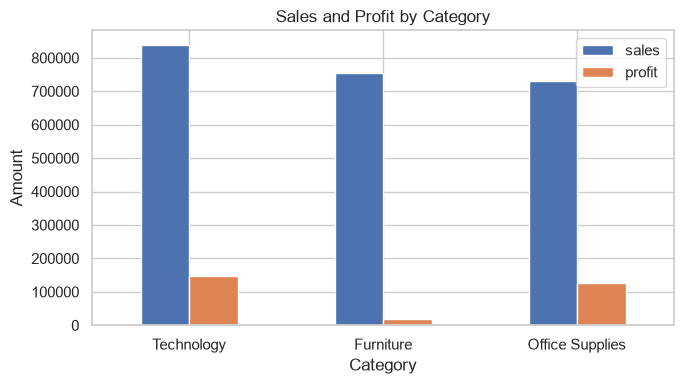

In [4]:
category_analysis= summarize_performance(df,"category")

print("\nQ2. WHICH CATEGORY GENERATES THE MOST SALES AND PROFIT?")
print("\n")
print(category_analysis)

category_analysis[["sales", "profit"]].plot(
    kind="bar",
    figsize=(7,4)
)

plt.title("Sales and Profit by Category")
plt.ylabel("Amount")
plt.xlabel("Category")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Q3. WHICH PRODUCTS HAVE HIGH SALES BUT LOW PROFIT?


In [5]:
product_analysis =(
    df.groupby(["product_id", "product_name"])
    .agg(
        sales=("sales", "sum"),
        profit=("profit", "sum"),
        quantity=("quantity", "sum"),
        order=("order_id", "nunique")        
    )
)

product_analysis["profit_margin_pct"] = (
    product_analysis["profit"]
    .div(product_analysis["sales"].replace(0, np.nan)
    .mul(100))
)

# Define high sales as above the median product-level sales.
# Flag products with high sales and non-positive total profit.

sales_threshold= product_analysis["sales"].median()

high_sales_low_profit =(
    product_analysis[
        (product_analysis["sales"]> sales_threshold)
        & (product_analysis["profit"]<=0)
    ]
    .sort_values("sales", ascending= False)
    
)

print("\nQ3-WHICH PRODUCTS HAVE HIGH SALES BUT LOW PROFIT?")
print("Product Sales Threshold:", sales_threshold)
print(high_sales_low_profit.head(20))

    


Q3-WHICH PRODUCTS HAVE HIGH SALES BUT LOW PROFIT?
Product Sales Threshold: 297.315
                                                                       sales  \
product_id      product_name                                                   
TEC-MA-10002412 Cisco TelePresence System EX90 Videoconferencin... 22,638.48   
OFF-BI-10004995 GBC DocuBind P400 Electric Binding System          17,965.07   
OFF-SU-10000151 High Speed Automatic Electric Letter Opener        17,030.31   
TEC-MA-10000822 Lexmark MX611dhe Monochrome Laser Printer          16,829.90   
OFF-SU-10002881 Martin Yale Chadless Opener Electric Letter Opener 16,656.20   
FUR-BO-10004834 Riverside Palais Royal Lawyers Bookcase, Royale... 15,610.97   
FUR-TA-10003473 Bretford Rectangular Conference Table Tops         13,565.57   
TEC-MA-10000418 Cubify CubeX 3D Printer Double Head Print          11,099.96   
FUR-TA-10000198 Chromcraft Bull-Nose Wood Oval Conference Table...  9,917.64   
FUR-TA-10001889 Bush Advantage Colle

#### Q4. WHICH REGIONS GENERATE THE MOST AND LEAST SALES/PROFIT?



Q4- Regional Performance
             sales     profit  quantity  order  profit_margin_pct
region                                                           
West    739,813.61 110,798.82     12466   1635              14.98
East    691,828.17  94,883.26     11159   1475              13.71
Central 503,170.67  39,865.31      8820   1179               7.92
South   391,721.91  46,749.43      6209    822              11.93


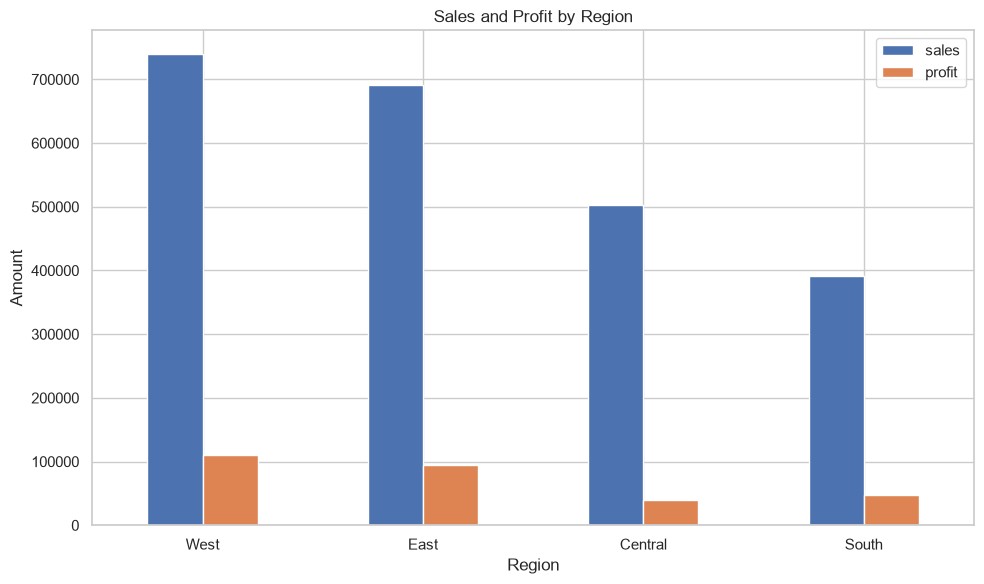

In [6]:
region_analysis =summarize_performance(df,"region")
print("\nQ4- Regional Performance")
print(region_analysis)

region_analysis[["sales", "profit"]].plot(
    kind="bar",
    figsize=(10, 6)
)
plt.title("Sales and Profit by Region")
plt.ylabel("Amount")
plt.xlabel("Region")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



#### Q5. WHICH REGION HAS HIGH SALES BUT WEAK PROFITABILITY?


In [7]:
print("\nQ5- Region Ranked by Profit Margin")
print(
    region_analysis.sort_values(
        "profit_margin_pct",
        ascending=True
    )
)


Q5- Region Ranked by Profit Margin
             sales     profit  quantity  order  profit_margin_pct
region                                                           
Central 503,170.67  39,865.31      8820   1179               7.92
South   391,721.91  46,749.43      6209    822              11.93
East    691,828.17  94,883.26     11159   1475              13.71
West    739,813.61 110,798.82     12466   1635              14.98


#### Q6. WHICH CUSTOMER SEGMENTS GENERATE THE MOST SALES?



Q6- Customer Segment Performance
                   sales     profit  quantity  order  profit_margin_pct
segment                                                                
Consumer    1,170,659.79 136,371.45     19844   2628              11.65
Corporate     715,806.13  94,249.64     11898   1552              13.17
Home Office   440,068.43  61,675.73      6912    931              14.02


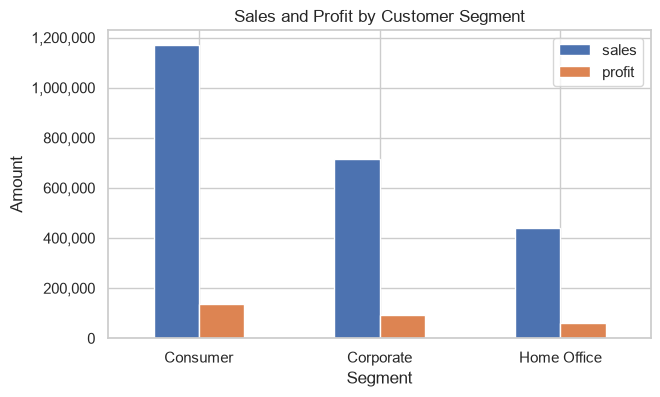

In [8]:
segment_analysis = summarize_performance(df, "segment")

print("\nQ6- Customer Segment Performance")
print(segment_analysis)

segment_analysis[["sales", "profit"]].plot(
    kind="bar",
    figsize=(7,4)
)

plt.title("Sales and Profit by Customer Segment")
plt.ylabel("Amount")
plt.xlabel("Segment")
plt.xticks(rotation=0)

plt.ticklabel_format(axis="y", style="plain")
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:,.0f}")
)
plt.show()

#### Q7. WHAT IS THE RELATIONSHIP BETWEEN DISCOUNT, SALES AND PROFIT?


Perfrmance by Discount Level
          records        sales     profit  quantity  order  profit_margin_pct
discount                                                                     
0.00         4925 1,105,323.79 326,718.59     18770   2714              29.56
0.10           96    54,952.50   9,099.97       377     91              16.56
0.15           52    27,558.52   1,418.99       198     51               5.15
0.20         3706   773,939.40  91,079.95     13856   2440              11.77
0.30          230   104,474.07 -10,513.45       855    214             -10.06
0.32           27    14,493.46  -2,391.14       105     27             -16.50
0.40          207   116,497.76 -23,086.37       789    186             -19.82
0.45           11     5,484.97  -2,493.11        45     10             -45.45
0.50           66    58,918.54 -20,506.43       241     64             -34.80
0.60          149     7,105.94  -6,164.35       554    138             -86.75
0.70          424    40,805.27 -40

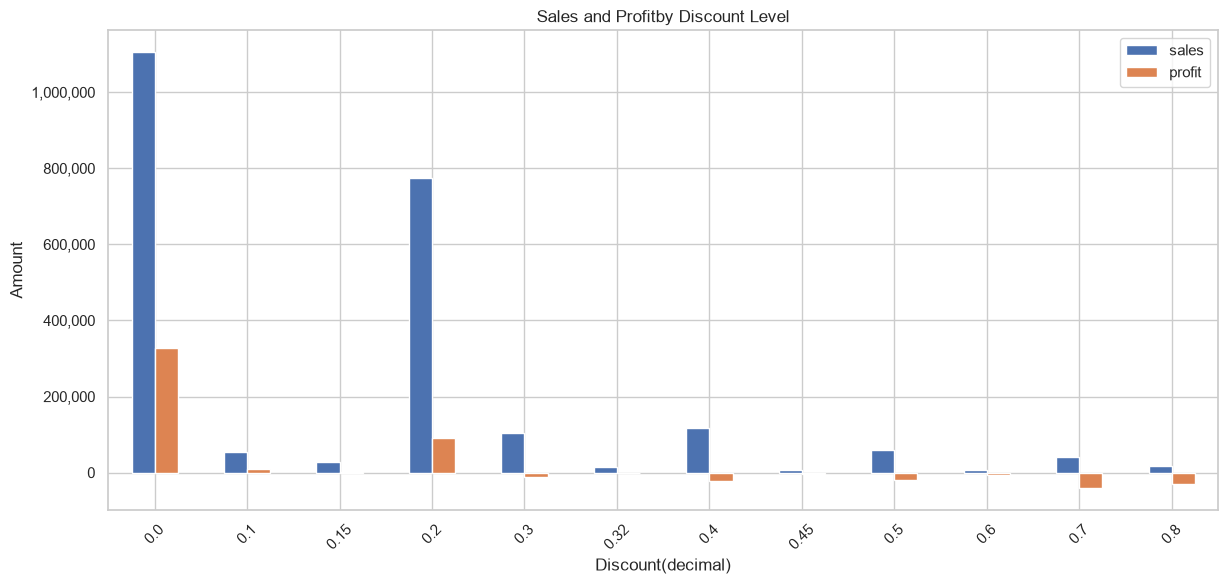

In [9]:
discount_analysis =(
    df.groupby("discount")
    .agg(
        records=("discount","size"),
        sales=("sales", "sum"),
        profit=("profit", "sum"),
        quantity=("quantity", "sum"),
        order=("order_id", "nunique")
    )
    .sort_index()
)

discount_analysis["profit_margin_pct"] =(
    discount_analysis["profit"]
    .div(discount_analysis["sales"].replace(0, np.nan))
    .mul(100)
)

print("\nPerfrmance by Discount Level")
print(discount_analysis)

discount_analysis[["sales", "profit"]].plot(
    kind="bar",
    figsize=(12,6)   
)

plt.title("Sales and Profitby Discount Level")
plt.xlabel("Discount(decimal)")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.tight_layout()

plt.ticklabel_format(axis="y", style="plain")
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:,.0f}")
)
plt.show()

### Q8. WHICH CATEGORY HAS THE LOWEST SALES?


In [10]:
print("\nQ8 - Category with Lowest Sales")
print(category_analysis.sort_values("sales").head(1))


Q8 - Category with Lowest Sales
                     sales     profit  quantity  order  profit_margin_pct
category                                                                 
Office Supplies 731,893.31 126,023.44     23268   3812              17.22


#### Q9. WHICH PRODUCT IS THE HERO PRODUCT?


In [11]:
print("\nTop 10 Product by Sales")
print(
    product_analysis.sort_values(
        "sales", ascending=False
    ).head(1)
)

print("\nTop Product by Quantity")
print(
    product_analysis.sort_values(
        "quantity", ascending=False
    ).head(1)
)


Top 10 Product by Sales
                                                          sales    profit  \
product_id      product_name                                                
TEC-CO-10004722 Canon imageCLASS 2200 Advanced Copier 61,599.82 25,199.93   

                                                       quantity  order  \
product_id      product_name                                             
TEC-CO-10004722 Canon imageCLASS 2200 Advanced Copier        20      5   

                                                       profit_margin_pct  
product_id      product_name                                              
TEC-CO-10004722 Canon imageCLASS 2200 Advanced Copier               0.00  

Top Product by Quantity
                                         sales  profit  quantity  order  \
product_id      product_name                                              
FUR-FU-10002501 Nu-Dell Executive Frame 924.74  285.65        84     11   

                                         pro

#### Q10. WHICH PRODUCTS HAVE THE LOWEST PROFIT?

In [12]:
print("\n10 Lowest Profit Product")
print(
    product_analysis.sort_values(
        "profit", ascending=True
    ).head(10)
)



10 Lowest Profit Product
                                                                       sales  \
product_id      product_name                                                   
TEC-MA-10000418 Cubify CubeX 3D Printer Double Head Print          11,099.96   
TEC-MA-10000822 Lexmark MX611dhe Monochrome Laser Printer          16,829.90   
TEC-MA-10004125 Cubify CubeX 3D Printer Triple Head Print           7,999.98   
FUR-TA-10000198 Chromcraft Bull-Nose Wood Oval Conference Table...  9,917.64   
FUR-TA-10001889 Bush Advantage Collection Racetrack Conference ...  9,544.73   
OFF-BI-10004995 GBC DocuBind P400 Electric Binding System          17,965.07   
TEC-MA-10002412 Cisco TelePresence System EX90 Videoconferencin... 22,638.48   
OFF-SU-10002881 Martin Yale Chadless Opener Electric Letter Opener 16,656.20   
FUR-TA-10001950 Balt Solid Wood Round Tables                        6,518.75   
FUR-TA-10004289 BoxOffice By Design Rectangular and Half-Moon M...  1,706.25   

             

#### Q11. WHICH SUB-CATEGORIES NEED PROFITABILITY REVIEW?


Q11 — SUB-CATEGORY PROFITABILITY
                  sales     profit  quantity  order  profit_margin_pct
sub-category                                                          
Tables       208,020.18 -17,753.21      1261    314              -8.53
Bookcases    115,361.20  -3,632.07       878    228              -3.15
Supplies      46,725.50  -1,171.39       653    189              -2.51
Machines     189,925.03   3,461.98       442    114               1.82
Chairs       335,768.25  27,223.53      2431    591               8.11
Storage      224,644.55  21,285.11      3191    787               9.48
Phones       331,842.64  45,050.83      3357    826              13.58
Furnishings   95,598.13  13,891.74      3799    919              14.53
Binders      207,354.88  31,426.10      6071   1339              15.16
Appliances   108,213.18  18,329.48      1750    459              16.94
Art           27,659.01   6,653.20      3092    756              24.05
Accessories  167,380.32  41,936.64      297

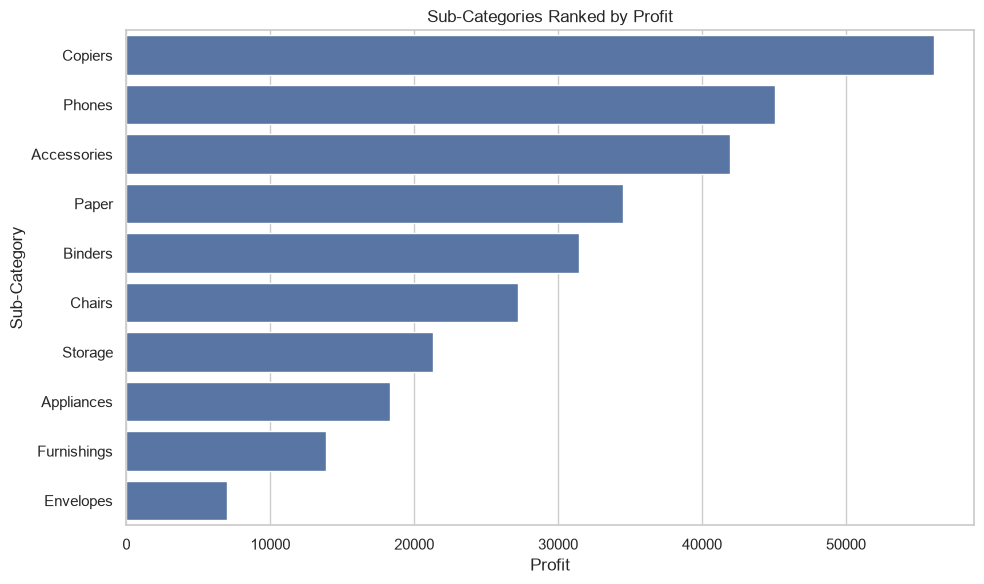

In [13]:
subcategory_analysis = summarize_performance(
    df, "sub-category"
)

print("\nQ11 — SUB-CATEGORY PROFITABILITY")

print(
    subcategory_analysis.sort_values(
        "profit_margin_pct",
        ascending=True
    )
)

plot_top_categories(
    subcategory_analysis.reset_index(),
    "sub-category",
    "profit",
    "Sub-Categories Ranked by Profit"
)

#### Q12. WHAT ARE THE MONTHLY SALES AND PROFIT TRENDS?



Q12 — MONTHLY PERFORMANCE
   year_month      sales    profit  orders
0     2023-01  14,501.61  2,533.84      32
1     2023-02   4,519.89    862.31      28
2     2023-03  56,950.36    699.00      73
3     2023-04  28,295.35  3,488.84      66
4     2023-05  26,319.77  3,196.39      72
5     2023-06  34,669.48  4,999.76      67
6     2023-07  33,946.39   -841.48      65
7     2023-08  28,918.34  5,765.22      75
8     2023-09  82,670.43  8,593.63     134
9     2023-10  32,413.34  3,469.17      81
10    2023-11  78,826.96  9,362.96     152
11    2023-12  72,008.31  9,554.66     150
12    2024-01  18,461.92 -3,189.80      31
13    2024-02  11,951.41  2,813.85      36
14    2024-03  39,978.63  9,930.61      81
15    2024-04  34,195.21  4,187.50      72
16    2024-05  30,246.95  4,677.14      75
17    2024-06  24,797.29  3,335.56      68
18    2024-07  28,765.33  3,288.65      66
19    2024-08  37,057.00  5,371.63      69
20    2024-09  64,627.05  8,220.03     142
21    2024-10  31,407.13  2

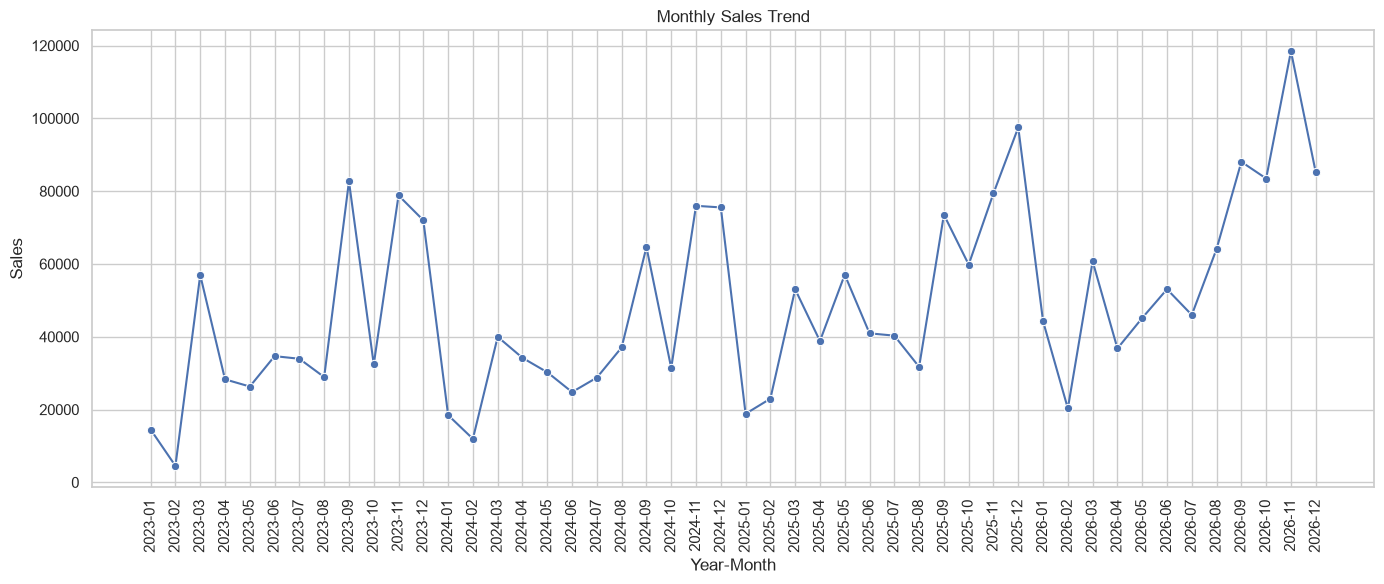

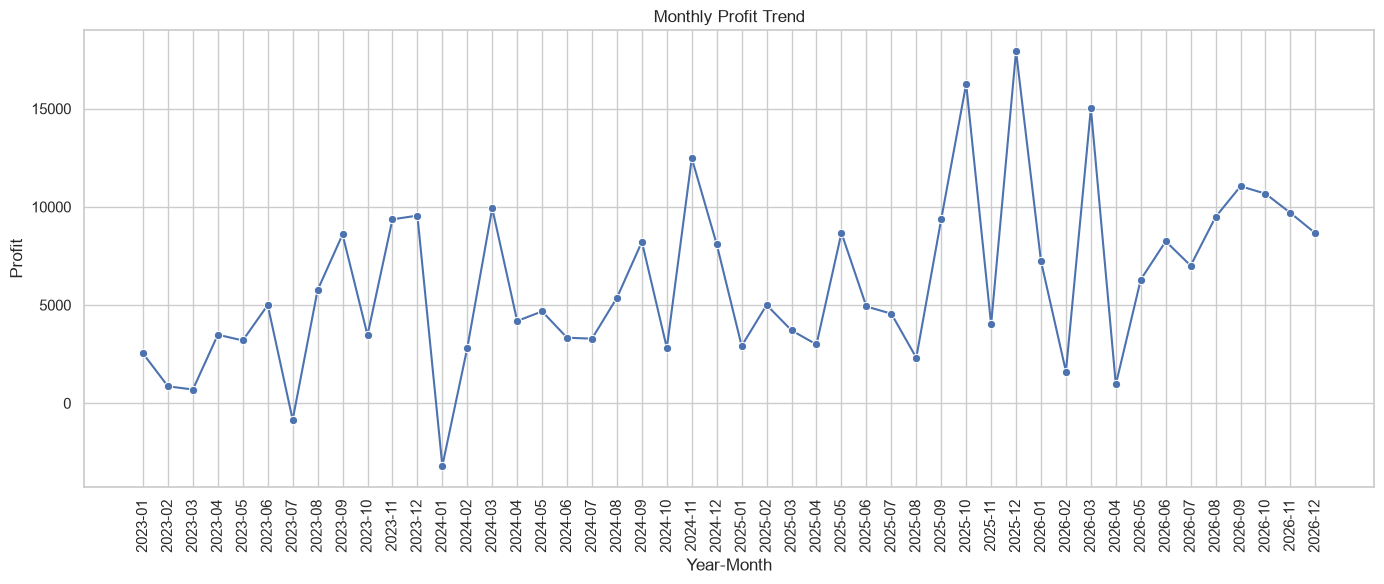

In [14]:
monthly_analysis = (
    df.assign(
        year_month=df["order_date"].dt.to_period("M")
    )
    .groupby("year_month")
    .agg(
        sales=("sales", "sum"),
        profit=("profit", "sum"),
        orders=("order_id", "nunique")
    )
    .reset_index()
)

monthly_analysis["year_month"] = (
    monthly_analysis["year_month"].astype(str)
)

print("\nQ12 — MONTHLY PERFORMANCE")
print(monthly_analysis)

plt.figure(figsize=(14, 6))
sns.lineplot(
    data=monthly_analysis,
    x="year_month",
    y="sales",
    marker="o"
)
plt.title("Monthly Sales Trend")
plt.xlabel("Year-Month")
plt.ylabel("Sales")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 6))
sns.lineplot(
    data=monthly_analysis,
    x="year_month",
    y="profit",
    marker="o"
)
plt.title("Monthly Profit Trend")
plt.xlabel("Year-Month")
plt.ylabel("Profit")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


#### Q13. WHICH RECORDS ARE LOSS-MAKING, AND WHERE?


In [15]:
loss_records = df[df["profit"] < 0].copy()

loss_summary = (
    loss_records.groupby("category")
    .agg(
        loss_making_rows=("profit", "size"),
        combined_profit_on_loss_rows=("profit", "sum")
    )
    .sort_values("combined_profit_on_loss_rows")
)

print("\nQ13 — LOSS-MAKING RECORDS BY CATEGORY")
print(loss_summary)

print("\nTotal loss-making rows:", len(loss_records))


Q13 — LOSS-MAKING RECORDS BY CATEGORY
                 loss_making_rows  combined_profit_on_loss_rows
category                                                       
Furniture                     732                    -61,675.18
Office Supplies               898                    -56,783.83
Technology                    271                    -38,579.92

Total loss-making rows: 1901


#### FINAL — EXPORT KEY RESULTS


In [16]:
with pd.ExcelWriter(
    "business_question_analysis.xlsx"
) as writer:
    overall_kpis.to_frame("value").to_excel(
        writer, sheet_name="Overall KPIs"
    )
    category_analysis.to_excel(
        writer, sheet_name="Category Analysis"
    )
    region_analysis.to_excel(
        writer, sheet_name="Region Analysis"
    )
    segment_analysis.to_excel(
        writer, sheet_name="Segment Analysis"
    )
    product_analysis.to_excel(
        writer, sheet_name="Product Analysis"
    )
    discount_analysis.to_excel(
        writer, sheet_name="Discount Analysis"
    )
    subcategory_analysis.to_excel(
        writer, sheet_name="Subcategory Analysis"
    )
    monthly_analysis.to_excel(
        writer, sheet_name="Monthly Analysis",
        index=False
    )
    loss_summary.to_excel(
        writer, sheet_name="Loss Analysis"
    )

print("\nAnalysis tables exported to business_question_analysis.xlsx")



Analysis tables exported to business_question_analysis.xlsx
